SMIL animation, written concurrently with the async helpers.

The drawing is animated by the SVG itself (open the saved file in a browser); the notebook shows a still.
Run it as ``python animation_async.py [OUTPUT_DIR]`` or open ``animation_async.ipynb``.

In [1]:
import asyncio
import sys
import tempfile
from collections.abc import Coroutine
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
from typing import Any

import svgwriter as svg
from svgwriter.io import write_many_async

Animation elements are children of the shape they animate: `AnimateTransform.spin` turns a blade,
`AnimateMotion` moves a dot along a path, `Animate` pulses its radius and `Set` hides it after a delay.
The function takes the spin period, so several variants can be made.

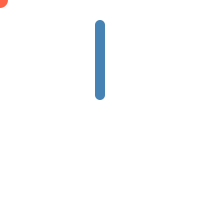

In [2]:
SIZE = 200
FRAMES = 3


def spinner(speed: float) -> svg.Svg:
    doc = svg.Document(SIZE, SIZE)
    blade = svg.Rect(95, 20, 10, 80, rx=5, fill="steelblue")
    blade.append(svg.AnimateTransform.spin(100, 100, dur=speed))
    doc.add(blade)

    track = doc.define(svg.Path(svg.PathBuilder().circle(100, 100, 70)))
    dot = doc.add(svg.Circle(0, 0, 8, fill="tomato"))
    dot.append(svg.AnimateMotion(svg.MPath(track), dur=speed * 2, repeat_count=float("inf")))
    dot.append(svg.Animate(attribute_name="r", values=[6, 10, 6], dur=1, repeat_count=float("inf")))
    dot.append(svg.Set("visibility", "hidden", begin=speed * 4, fill=svg.AnimationFill.FREEZE))
    return doc.root


spinner(1.0)

`write_many_async` writes several documents concurrently. A script starts an event loop with
`asyncio.run`, but Jupyter already runs one, so `run` falls back to a helper thread with its own loop.

In [3]:
def run(coroutine: Coroutine[Any, Any, Any]) -> Any:
    try:
        asyncio.get_running_loop()
    except RuntimeError:
        return asyncio.run(coroutine)
    with ThreadPoolExecutor(1) as pool:
        return pool.submit(asyncio.run, coroutine).result()


async def write_all(out_dir: Path) -> list[Path]:
    targets = {out_dir / f"spinner_{i}.svg": spinner(1.0 + i) for i in range(FRAMES)}
    await write_many_async(targets)
    return list(targets)

Write the three spinners. Pass a folder as the first argument to choose where they go.

In [4]:
args = sys.argv[1:2]
out = Path(args[0]) if args and not args[0].startswith("-") else Path(tempfile.mkdtemp(prefix="svgwriter-"))
written = run(write_all(out))
print("saved", ", ".join(path.name for path in written))

saved spinner_0.svg, spinner_1.svg, spinner_2.svg
